In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score)
import joblib

In [2]:
train = pd.read_csv("../dataset/train.csv")
test = pd.read_csv("../dataset/test.csv")

print("Training Data:", train.shape)
print("Testing Data:", test.shape)

train.head()

Training Data: (22750, 9)
Testing Data: (12250, 8)


,Employee ID,Date of Joining,Gender,Company Type,WFH Setup Available,Designation,Resource Allocation,Mental Fatigue Score,Burn Rate
0,fffe32003000360033003200,2008-09-30,Female,Service,No,2.0,3.0,3.8,0.16
1,fffe3700360033003500,2008-11-30,Male,Service,Yes,1.0,2.0,5.0,0.36
2,fffe31003300320037003900,2008-03-10,Female,Product,Yes,2.0,NaN,5.8,0.49
3,fffe32003400380032003900,2008-11-03,Male,Service,Yes,1.0,1.0,2.6,0.20
4,fffe31003900340031003600,2008-07-24,Female,Service,No,3.0,7.0,6.9,0.52


In [3]:
print(train.info())
print("\nMissing Values:\n", train.isnull().sum())
print("\nStatistical Summary:\n", train.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22750 entries, 0 to 22749
Data columns (total 9 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Employee ID           22750 non-null  object 
 1   Date of Joining       22750 non-null  object 
 2   Gender                22750 non-null  object 
 3   Company Type          22750 non-null  object 
 4   WFH Setup Available   22750 non-null  object 
 5   Designation           22750 non-null  float64
 6   Resource Allocation   21369 non-null  float64
 7   Mental Fatigue Score  20633 non-null  float64
 8   Burn Rate             21626 non-null  float64
dtypes: float64(4), object(5)
memory usage: 1.6+ MB
None

Missing Values:
 Employee ID                0
Date of Joining            0
Gender                     0
Company Type               0
WFH Setup Available        0
Designation                0
Resource Allocation     1381
Mental Fatigue Score    2117
Burn Rate               

In [4]:
features = [
    "Company Type",
    "WFH Setup Available",
    "Designation",
    "Resource Allocation",
    "Mental Fatigue Score"
]

train = train.dropna(subset=["Burn Rate"])

X = train[features]
y = train["Burn Rate"]

X_test_final = test[features]

In [5]:
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Training:", X_train.shape)
print("Testing:", X_val.shape)

Training: (17300, 5)
Testing: (4326, 5)


In [6]:
numeric = ["Designation", "Resource Allocation", "Mental Fatigue Score"]

categorical = ["Company Type", "WFH Setup Available"]

preprocessor = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), numeric),
    ("cat", make_pipeline(
        SimpleImputer(strategy="most_frequent"),
        OneHotEncoder(handle_unknown="ignore")
    ), categorical)
])

model = make_pipeline(
    preprocessor,
    RandomForestRegressor(
        n_estimators=100,
        max_depth=10,
        random_state=42,
        n_jobs=-1
    )
)

In [7]:
model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [8]:
y_pred = model.predict(X_val)

results = pd.DataFrame({
    "Actual": y_val.values,
    "Predicted": y_pred
})

results.head(10)

,Actual,Predicted
0,0.56,0.474761
1,0.48,0.536281
2,0.08,0.064060
3,0.54,0.510418
4,0.76,0.814655
5,0.44,0.461178
6,0.53,0.417868
7,0.42,0.407516
8,0.65,0.598909
9,0.74,0.711173


In [9]:
print("MAE:", round(mean_absolute_error(y_val, y_pred), 4))

print("RMSE:", round(np.sqrt(mean_squared_error(y_val, y_pred)), 4))

print("R2 Score:", round(r2_score(y_val, y_pred), 4))

MAE: 0.0472
RMSE: 0.0604
R2 Score: 0.9042


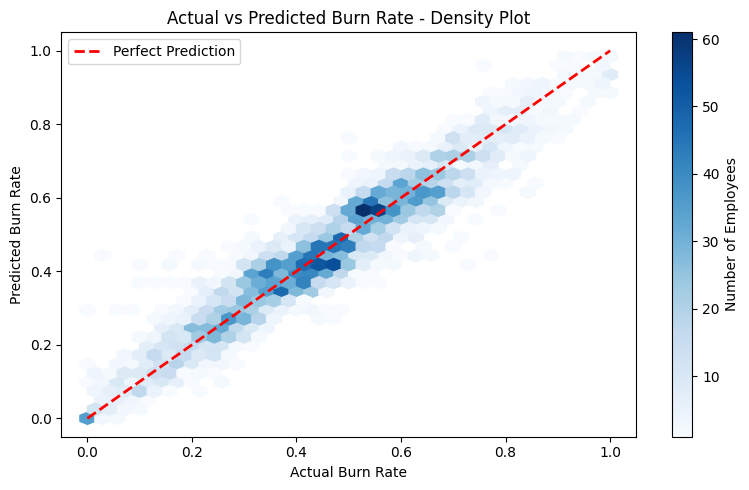

In [10]:
plt.figure(figsize=(8, 5))

plt.hexbin(
    y_val,
    y_pred,
    gridsize=35,
    cmap="Blues",
    mincnt=1
)

plt.colorbar(label="Number of Employees")

plt.plot(
    [0, 1],
    [0, 1],
    color="red",
    linestyle="--",
    linewidth=2,
    label="Perfect Prediction"
)

plt.xlabel("Actual Burn Rate")
plt.ylabel("Predicted Burn Rate")
plt.title("Actual vs Predicted Burn Rate - Density Plot")

plt.legend()
plt.tight_layout()
plt.show()

In [11]:
model.fit(X, y)
joblib.dump(model, "employee_burnout_model.pkl")

print("Final model trained and saved successfully!")

Final model trained and saved successfully!


In [12]:
model = joblib.load("employee_burnout_model.pkl")
company = input("Enter Company Type (Service/Product): ")
wfh = input("Enter WFH Setup (Yes/No): ")
designation = float(input("Enter Designation: "))
allocation = float(input("Enter Resource Allocation: "))
fatigue = float(input("Enter Mental Fatigue Score: "))

new_employee = pd.DataFrame([{
    "Company Type": company,
    "WFH Setup Available": wfh,
    "Designation": designation,
    "Resource Allocation": allocation,
    "Mental Fatigue Score": fatigue
}])

prediction = model.predict(new_employee)[0]
print("\nEMPLOYEE BURNOUT PREDICTION")
print("---------------------------")
print("Predicted Burn Rate:", round(prediction, 3))

Enter Company Type (Service/Product):  service
Enter WFH Setup (Yes/No):  no
Enter Designation:  2
Enter Resource Allocation:  4
Enter Mental Fatigue Score:  5



EMPLOYEE BURNOUT PREDICTION
---------------------------
Predicted Burn Rate: 0.377
